# CosmoSIS likelihood wiring sample

This notebook is a self-contained wiring sample for calling Dark Emulator2 from a CosmoSIS likelihood pipeline. It evaluates two toy likelihoods: one based on `P(k,z)` and one based on a direct `C_ell` output.

This is not a survey analysis. Real data vectors, covariances, nuisance parameters, scale cuts, and emulator/theory uncertainty treatment must be supplied by the downstream analysis.

For production analyses, the recommended route is to pass `P(k,z)` to downstream CosmoSIS projection and likelihood modules. The direct `C_ell` example is included only for workflows that explicitly expect a precomputed angular spectrum.

CosmoSIS documentation: https://cosmosis.readthedocs.io/en/latest/


## Setup

Use the same Python environment as this notebook kernel.


In [1]:
# %pip install cosmosis dark_emulator2

In [2]:
import cosmosis
import dark_emulator2

In [3]:
from pathlib import Path

runtime_dir = Path("cosmosis_dq2_runtime_toy")
runtime_dir.mkdir(exist_ok=True)

In [4]:
import subprocess
from pathlib import Path


def run_cosmosis(ini_file):
    ini_file = Path(ini_file)
    result = subprocess.run(
        ["cosmosis", str(ini_file)],
        text=True,
        capture_output=True,
    )

    if result.returncode != 0:
        tail = "\n".join((result.stdout + result.stderr).splitlines()[-80:])
        raise RuntimeError(f"CosmoSIS failed for {ini_file}\n\n{tail}")

    print(f"completed: {ini_file}")

## Dark Emulator2 and toy likelihood modules

In [5]:
%%writefile cosmosis_dq2_runtime_toy/dq2_cosmosis.py
import numpy as np
from cosmosis.datablock import option_section
from dark_emulator2 import DarkEmulator2

COSMO = "cosmological_parameters"
SUPPORT = "dq2_support"


def setup(options):
    z = np.linspace(
        float(options[option_section, "zmin"]),
        float(options[option_section, "zmax"]),
        int(options[option_section, "nz"]),
    )
    k_h = np.logspace(
        np.log10(float(options[option_section, "kmin_h"])),
        np.log10(float(options[option_section, "kmax_h"])),
        int(options[option_section, "nk"]),
    )

    return {
        "emu": DarkEmulator2(),
        "z": z,
        "k_h": k_h,
        "pk_type": str(options[option_section, "pk_type"]),
    }


def execute(block, config):
    param = {
        "Omega_m": block[COSMO, "omega_m"],
        "h0": block[COSMO, "h0"],
        "omega_b": block[COSMO, "omega_b"],
        "sigma8": block[COSMO, "sigma8"],
        "ns": block[COSMO, "n_s"],
        "Mnu": block[COSMO, "mnu"],
        "Omega_k": block[COSMO, "omega_k"],
        "Omega_de": 1.0 - block[COSMO, "omega_m"] - block[COSMO, "omega_k"],
        "w0": block[COSMO, "w"],
        "wa": block[COSMO, "wa"],
    }

    emu = config["emu"]
    z = config["z"]
    k_h = config["k_h"]

    in_support = int(emu.is_in_support(param))
    block[SUPPORT, "in_support"] = in_support

    if in_support:
        _, pk_nl = emu.get_pk(
            param,
            zred=z,
            klist=k_h,
            pk_type=config["pk_type"],
        )
    else:
        pk_nl = np.full((len(z), len(k_h)), np.nan)

    block["matter_power_nl", "z"] = z
    block["matter_power_nl", "k_h"] = k_h
    block["matter_power_nl", "p_k"] = pk_nl

    return 0

Overwriting cosmosis_dq2_runtime_toy/dq2_cosmosis.py


In [6]:
%%writefile cosmosis_dq2_runtime_toy/toy_pk_likelihood.py
from pathlib import Path
import numpy as np
from cosmosis.datablock import option_section
from dark_emulator2 import DarkEmulator2

COSMO = "cosmological_parameters"
LIKE = "likelihoods"
SUPPORT = "dq2_support"


def _as_1d_pk(pk):
    pk = np.asarray(pk).squeeze()
    if pk.ndim != 1:
        raise ValueError(f"Expected a one-dimensional P(k) array after squeezing, got shape {pk.shape}.")
    return pk


def setup(options):
    output = str(options[option_section, "output"])
    Path(output).unlink(missing_ok=True)

    k_model = np.logspace(-3, 1, 201)
    data_indices = np.linspace(50, 150, 12, dtype=int)
    k_data = k_model[data_indices]
    z_data = np.array([0.0])

    data_cosmology = {
        "Omega_m": 0.20,
        "h0": 0.6723,
        "omega_b": 0.02225,
        "sigma8": 1.00,
        "ns": 0.9645,
        "Mnu": 0.06,
        "Omega_k": 0.0,
        "Omega_de": 1.0 - 0.20,
        "w0": -1.0,
        "wa": 0.0,
    }

    _, pk_model = DarkEmulator2().get_pk(
        data_cosmology,
        zred=z_data,
        klist=k_model,
        pk_type="total",
    )

    return {
        "k_data": k_data,
        "log_pk_data": np.log(_as_1d_pk(pk_model)[data_indices]),
        "sigma_logpk": 0.03,
        "output": output,
        "bad_chi2": 1.0e12,
    }


def execute(block, config):
    in_support = int(block[SUPPORT, "in_support"])

    if in_support:
        k_h = block["matter_power_nl", "k_h"]
        pk = _as_1d_pk(block["matter_power_nl", "p_k"])

        log_pk_model = np.interp(
            np.log(config["k_data"]),
            np.log(k_h),
            np.log(pk),
        )

        chi2 = np.sum(((log_pk_model - config["log_pk_data"]) / config["sigma_logpk"]) ** 2)
    else:
        chi2 = config["bad_chi2"]

    loglike = -0.5 * chi2
    block[LIKE, "toy_pk_like"] = loglike

    with open(config["output"], "a") as f:
        f.write(
            f"{block[COSMO, 'omega_m']:.8e} "
            f"{block[COSMO, 'sigma8']:.8e} "
            f"{in_support:d} "
            f"{loglike:.8e} "
            f"{chi2:.8e}\n"
        )

    return 0

Overwriting cosmosis_dq2_runtime_toy/toy_pk_likelihood.py


In [7]:
%%writefile cosmosis_dq2_runtime_toy/dq2_cl_cosmosis.py
import numpy as np
from cosmosis.datablock import option_section
from dark_emulator2 import DarkEmulator2

COSMO = "cosmological_parameters"
SUPPORT = "dq2_support"


def setup(options):
    z = np.linspace(
        float(options[option_section, "zmin"]),
        float(options[option_section, "zmax"]),
        int(options[option_section, "nz"]),
    )
    k_h = np.logspace(
        np.log10(float(options[option_section, "kmin_h"])),
        np.log10(float(options[option_section, "kmax_h"])),
        int(options[option_section, "nk"]),
    )
    ell = np.logspace(
        np.log10(float(options[option_section, "ell_min"])),
        np.log10(float(options[option_section, "ell_max"])),
        int(options[option_section, "nell"]),
    )

    return {
        "emu": DarkEmulator2(),
        "z": z,
        "k_h": k_h,
        "ell": ell,
        "pk_type": str(options[option_section, "pk_type"]),
    }


def execute(block, config):
    param = {
        "Omega_m": block[COSMO, "omega_m"],
        "h0": block[COSMO, "h0"],
        "omega_b": block[COSMO, "omega_b"],
        "sigma8": block[COSMO, "sigma8"],
        "ns": block[COSMO, "n_s"],
        "Mnu": block[COSMO, "mnu"],
        "Omega_k": block[COSMO, "omega_k"],
        "Omega_de": 1.0 - block[COSMO, "omega_m"] - block[COSMO, "omega_k"],
        "w0": block[COSMO, "w"],
        "wa": block[COSMO, "wa"],
    }

    emu = config["emu"]
    ell = config["ell"]

    in_support = int(emu.is_in_support(param))
    block[SUPPORT, "in_support"] = in_support

    if in_support:
        ell, cl = emu.get_cl_limber(
            param,
            zlist=config["z"],
            klist=config["k_h"],
            llist=ell,
            pk_type=config["pk_type"],
        )
    else:
        cl = np.full_like(ell, np.nan, dtype=float)

    block["shear_cl", "ell"] = ell
    block["shear_cl", "bin_1_1"] = cl
    block["shear_cl", "nbin"] = 1

    return 0

Overwriting cosmosis_dq2_runtime_toy/dq2_cl_cosmosis.py


In [8]:
%%writefile cosmosis_dq2_runtime_toy/toy_cl_likelihood.py
from pathlib import Path
import numpy as np
from cosmosis.datablock import option_section
from dark_emulator2 import DarkEmulator2

COSMO = "cosmological_parameters"
LIKE = "likelihoods"
SUPPORT = "dq2_support"


def _as_1d(x):
    return np.asarray(x).squeeze()


def setup(options):
    output = str(options[option_section, "output"])
    Path(output).unlink(missing_ok=True)

    z = np.linspace(0.0, 2.0, 101)
    k_h = np.logspace(-3, 1, 201)
    ell = np.logspace(1, 4, 40)

    data_cosmology = {
        "Omega_m": 0.20,
        "h0": 0.6723,
        "omega_b": 0.02225,
        "sigma8": 1.00,
        "ns": 0.9645,
        "Mnu": 0.06,
        "Omega_k": 0.0,
        "Omega_de": 1.0 - 0.20,
        "w0": -1.0,
        "wa": 0.0,
    }

    _, cl_data = DarkEmulator2().get_cl_limber(
        data_cosmology,
        zlist=z,
        klist=k_h,
        llist=ell,
        pk_type="total",
    )

    return {
        "ell_data": ell,
        "log_cl_data": np.log(_as_1d(cl_data)),
        "sigma_logcl": 0.05,
        "output": output,
        "bad_chi2": 1.0e12,
    }


def execute(block, config):
    in_support = int(block[SUPPORT, "in_support"])

    if in_support:
        ell = _as_1d(block["shear_cl", "ell"])
        cl = _as_1d(block["shear_cl", "bin_1_1"])

        log_cl_model = np.interp(
            np.log(config["ell_data"]),
            np.log(ell),
            np.log(cl),
        )

        chi2 = np.sum(((log_cl_model - config["log_cl_data"]) / config["sigma_logcl"]) ** 2)
    else:
        chi2 = config["bad_chi2"]

    loglike = -0.5 * chi2
    block[LIKE, "toy_cl_like"] = loglike

    with open(config["output"], "a") as f:
        f.write(
            f"{block[COSMO, 'omega_m']:.8e} "
            f"{block[COSMO, 'sigma8']:.8e} "
            f"{in_support:d} "
            f"{loglike:.8e} "
            f"{chi2:.8e}\n"
        )

    return 0

Overwriting cosmosis_dq2_runtime_toy/toy_cl_likelihood.py


## Parameter grid

In [9]:
%%writefile cosmosis_dq2_runtime_toy/values.ini
[cosmological_parameters]
omega_m = 0.05000000 0.20000000 0.65000000
h0 = 0.6723
omega_b = 0.02225
sigma8 = 0.30000000 1.00000000 1.50000000
n_s = 0.9645
mnu = 0.06
omega_k = 0.0
w = -1.0
wa = 0.0


Overwriting cosmosis_dq2_runtime_toy/values.ini


## Plotting

The color shows `log10(1 + Delta chi2)`. The star marks the cosmology used to generate the fake data vector. The black curve marks the practical Dark Emulator2 support boundary; points outside it are not evaluated.


In [10]:
import numpy as np
import matplotlib.pyplot as plt


def make_grids(evals):
    omega_m = evals[:, 0]
    sigma8 = evals[:, 1]
    in_support = evals[:, 2].astype(bool)
    chi2 = evals[:, 4]

    omega_grid = np.unique(omega_m)
    sigma8_grid = np.unique(sigma8)

    chi2_grid = np.full((len(sigma8_grid), len(omega_grid)), np.nan)
    support_grid = np.full_like(chi2_grid, False, dtype=bool)

    for om, s8, ok, c2 in zip(omega_m, sigma8, in_support, chi2):
        iom = int(np.where(omega_grid == om)[0][0])
        is8 = int(np.where(sigma8_grid == s8)[0][0])
        support_grid[is8, iom] = ok
        if ok:
            chi2_grid[is8, iom] = c2

    delta_chi2 = chi2_grid - np.nanmin(chi2_grid)
    return omega_grid, sigma8_grid, delta_chi2, support_grid


def plot_likelihood_plane(evals, title, data_omega_m, data_sigma8, saturation_percentile=94.0):
    omega_grid, sigma8_grid, delta_chi2, support_grid = make_grids(evals)
    delta_chi2_masked = np.where(support_grid, delta_chi2, np.nan)

    display = np.log10(1.0 + delta_chi2_masked)
    vmax = np.nanpercentile(display, saturation_percentile)
    levels = np.linspace(0.0, vmax, 40)

    fig, ax = plt.subplots(figsize=(6.2, 4.6), constrained_layout=True)

    cf = ax.contourf(
        omega_grid,
        sigma8_grid,
        display,
        levels=levels,
        cmap="viridis_r",
        extend="max",
    )
    fig.colorbar(
        cf,
        ax=ax,
        label=rf"$\log_{{10}}(1+\Delta\chi^2)$, top {100.0 - saturation_percentile:.0f}% saturated",
    )

    if np.any(support_grid) and not np.all(support_grid):
        ax.contour(
            omega_grid,
            sigma8_grid,
            support_grid.astype(float),
            levels=[0.5],
            colors="black",
            linewidths=1.2,
        )

    ax.scatter(
        [data_omega_m],
        [data_sigma8],
        s=110,
        marker="*",
        color="white",
        edgecolor="black",
        linewidth=1.0,
        zorder=6,
    )
    ax.annotate(
        "data-generating point",
        xy=(data_omega_m, data_sigma8),
        xytext=(data_omega_m + 0.045, data_sigma8 + 0.075),
        arrowprops={"arrowstyle": "-", "lw": 0.8},
    )

    ax.set_xlabel(r"$\Omega_m$")
    ax.set_ylabel(r"$\sigma_8$")
    ax.set_title(title)
    ax.grid(alpha=0.15)

    plt.show()


## `P(k)` example

In [11]:
%%writefile cosmosis_dq2_runtime_toy/pipeline_pk.ini
[runtime]
sampler = grid

[pipeline]
modules = dq2 toy_pk
values = cosmosis_dq2_runtime_toy/values.ini
likelihoods = toy_pk
debug = F
timing = F

[dq2]
file = cosmosis_dq2_runtime_toy/dq2_cosmosis.py
zmin = 0.0
zmax = 0.0
nz = 1
kmin_h = 1.0e-3
kmax_h = 10.0
nk = 201
pk_type = total

[toy_pk]
file = cosmosis_dq2_runtime_toy/toy_pk_likelihood.py
output = cosmosis_dq2_runtime_toy/toy_pk_likelihood_evals.txt

[grid]
nsample_dimension = 61

[output]
filename = cosmosis_dq2_runtime_toy/cosmosis_grid_pk_output.txt
format = text

Overwriting cosmosis_dq2_runtime_toy/pipeline_pk.ini


In [12]:
run_cosmosis("cosmosis_dq2_runtime_toy/pipeline_pk.ini")

completed: cosmosis_dq2_runtime_toy/pipeline_pk.ini


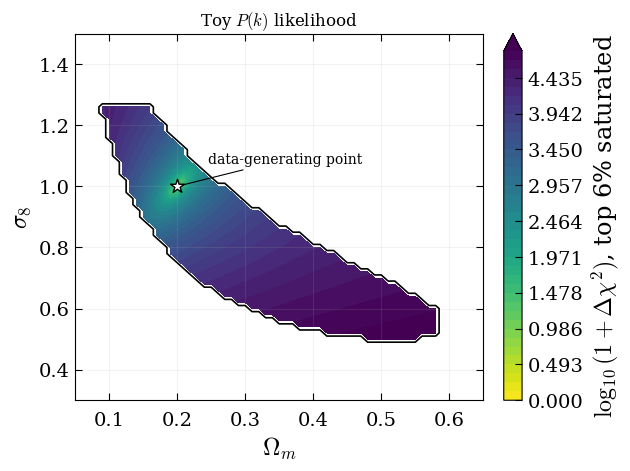

In [13]:
evals = np.loadtxt("cosmosis_dq2_runtime_toy/toy_pk_likelihood_evals.txt")
plot_likelihood_plane(evals, title=r"Toy $P(k)$ likelihood", data_omega_m=0.20, data_sigma8=1.00)

## `C_ell` example

In [14]:
%%writefile cosmosis_dq2_runtime_toy/pipeline_cl.ini
[runtime]
sampler = grid

[pipeline]
modules = dq2_cl toy_cl
values = cosmosis_dq2_runtime_toy/values.ini
likelihoods = toy_cl
debug = F
timing = F

[dq2_cl]
file = cosmosis_dq2_runtime_toy/dq2_cl_cosmosis.py
zmin = 0.0
zmax = 2.0
nz = 101
kmin_h = 1.0e-3
kmax_h = 10.0
nk = 201
ell_min = 10.0
ell_max = 1.0e4
nell = 40
pk_type = total

[toy_cl]
file = cosmosis_dq2_runtime_toy/toy_cl_likelihood.py
output = cosmosis_dq2_runtime_toy/toy_cl_likelihood_evals.txt

[grid]
nsample_dimension = 61

[output]
filename = cosmosis_dq2_runtime_toy/cosmosis_grid_cl_output.txt
format = text

Overwriting cosmosis_dq2_runtime_toy/pipeline_cl.ini


In [15]:
run_cosmosis("cosmosis_dq2_runtime_toy/pipeline_cl.ini")

completed: cosmosis_dq2_runtime_toy/pipeline_cl.ini


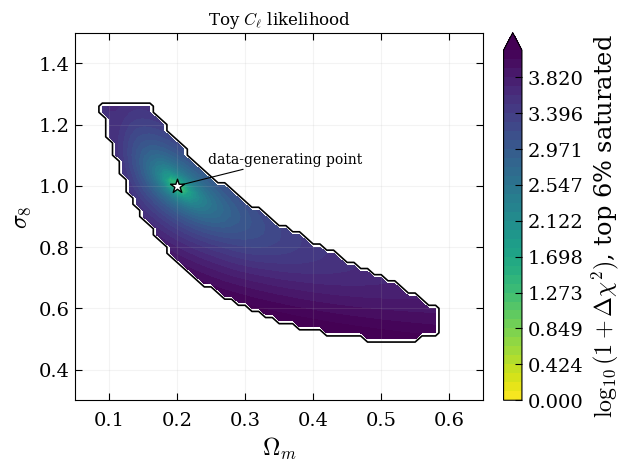

In [16]:
evals = np.loadtxt("cosmosis_dq2_runtime_toy/toy_cl_likelihood_evals.txt")
plot_likelihood_plane(evals, title=r"Toy $C_\ell$ likelihood", data_omega_m=0.20, data_sigma8=1.00)

## Notes for real data analyses

Keep the Dark Emulator2 theory module, but replace the fake data vector, toy error, nuisance parameters, scale cuts, and section conventions with those required by the target CosmoSIS likelihood.

For production use, pass `P(k,z)` to downstream CosmoSIS projection and likelihood modules. Use a direct `C_ell` block only if the target workflow explicitly expects a precomputed angular spectrum. Emulator or theory uncertainty should be handled downstream through a validation-based theory covariance, nuisance model, or scale cut.
